# v3 - 4. Sanity check: shuffled labels
The same cross-validation, but the TRAINING labels are shuffled. A model that learned anything real now has nothing to learn, so accuracy must fall to the majority-class rate (~60 %). **If a model stays high here, there is leakage.**

In [1]:
import os, sys
from pathlib import Path
os.environ["TOADWATCH_VERSION"] = "v3"          # selects the strict "true accuracy" study (v3); keep this line first
sys.path.insert(0, str(Path.cwd().parent))       # notebooks live in ToadWatch_PR/notebooks
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.width", 190); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 120)
from toadwatch import config as C, workflow_v3 as W, protocol_v3 as P, charts_v3 as CH, reporting as R
print("version:", C.VERSION, "| seed:", C.SEED, "| outputs:", C.OUTPUTS_DIR)

version: v3 | seed: 2028 | outputs: /home/rush/Downloads/Fase/ToadWatch_PR/outputs/v3


In [2]:
shuf = W.shuffle_check()     # ~10 minutes
shuf[['accuracy_mean', 'accuracy_std', 'f1_mean', 'majority_class_rate']].round(3)

  fold 0 done


  fold 1 done


  fold 2 done


  fold 3 done


,accuracy_mean,accuracy_std,f1_mean,majority_class_rate
variant,,,,
call_only,0.541,0.117,0.453,0.601
message_only,0.510,0.027,0.428,0.601
combined_early,0.527,0.058,0.441,0.601
combined_text,0.484,0.049,0.404,0.601


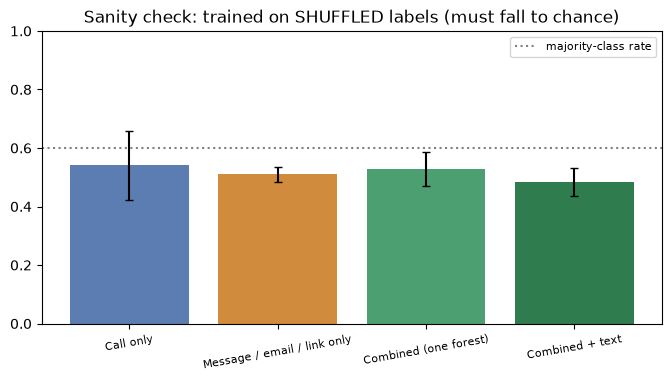

PASS - every model falls to chance with shuffled labels


In [3]:
CH.plot_shuffle(shuf, 'v3_04_shuffle_check'); plt.show()
ok = (shuf['accuracy_mean'] < shuf['majority_class_rate'] + 0.05).all()
print('PASS - every model falls to chance with shuffled labels' if ok else 'FAIL - some model stays above chance with shuffled labels: investigate leakage')